# ML Assignment 3 - Classification
## Breast Cancer Classification Using Supervised Learning

**Objective:** Train and compare five supervised classification algorithms using the Wisconsin Diagnostic Breast Cancer dataset from scikit-learn.

**Algorithms:** Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), and k-Nearest Neighbors (k-NN).

**Target labels:** `0 = malignant`, `1 = benign`.

> Educational exercise only; this is not a medical diagnostic tool.

## 1. Import libraries and load the dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
# Load the built-in scikit-learn dataset
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target")

print("Dataset shape:", X.shape)
print("Target classes (0 = malignant, 1 = benign):")
print(pd.Series(y).value_counts().sort_index().rename(index={
    0: "malignant (0)", 1: "benign (1)"
}))
print("\nFirst five rows:")
display(X.head())
print("\nMissing values in features:", int(X.isna().sum().sum()))

Dataset shape: (569, 30)
Target classes (0 = malignant, 1 = benign):
target
malignant (0)    212
benign (1)       357
Name: count, dtype: int64

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Missing values in features: 0


## 2. Preprocessing and train/test split

- **Missing values:** Median imputation is included to make the workflow robust. The built-in dataset normally has no missing values.
- **Feature scaling:** Standardisation is used for Logistic Regression, SVM, and k-NN because these methods are sensitive to feature magnitudes. Tree models do not require scaling.
- **Train/test split:** 80% training and 20% testing, with stratification to preserve class proportions.
- **Data leakage prevention:** Imputation and scaling are inside pipelines, so they are fitted on training data only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training observations: 455
Testing observations: 114

Training class proportions:
target
1    0.626
0    0.374
Name: proportion, dtype: float64

Testing class proportions:
target
1    0.632
0    0.368
Name: proportion, dtype: float64


## 3. Classification algorithms

1. **Logistic Regression:** Estimates the probability of belonging to a class; a useful baseline for binary classification.
2. **Decision Tree:** Learns feature-based decision rules; interpretable but can overfit.
3. **Random Forest:** Combines many decision trees to improve generalisation.
4. **SVM:** Finds a decision boundary with a large margin; scaling is important.
5. **k-NN:** Predicts using the labels of nearby training observations; scaling is important because it uses distances.

In [5]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(n_estimators=300, random_state=42))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=42))
    ]),
    "k-NN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Models ready:", ", ".join(models.keys()))

Models ready: Logistic Regression, Decision Tree, Random Forest, SVM, k-NN


## 4. Train and evaluate the models

Metrics:
- **Accuracy:** proportion of predictions that are correct.
- **Precision:** proportion of predicted positive cases that are truly positive.
- **Recall:** proportion of actual positive cases correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** ability of predicted probabilities to rank the two classes.

Here, the positive class (`1`) is **benign**. Review the malignant-class recall and confusion matrices too; accuracy alone is not enough in a medical context.

In [6]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

C:\Users\azilk\PycharmProjects\WelcomeScreen\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.9954
1,SVM,0.9825,0.9861,0.9861,0.9861,0.9950
2,k-NN,0.9561,0.9589,0.9722,0.9655,0.9788
3,Random Forest,0.9474,0.9583,0.9583,0.9583,0.9937
4,Decision Tree,0.9123,0.9559,0.9028,0.9286,0.9157


## 5. Visual comparison of model performance

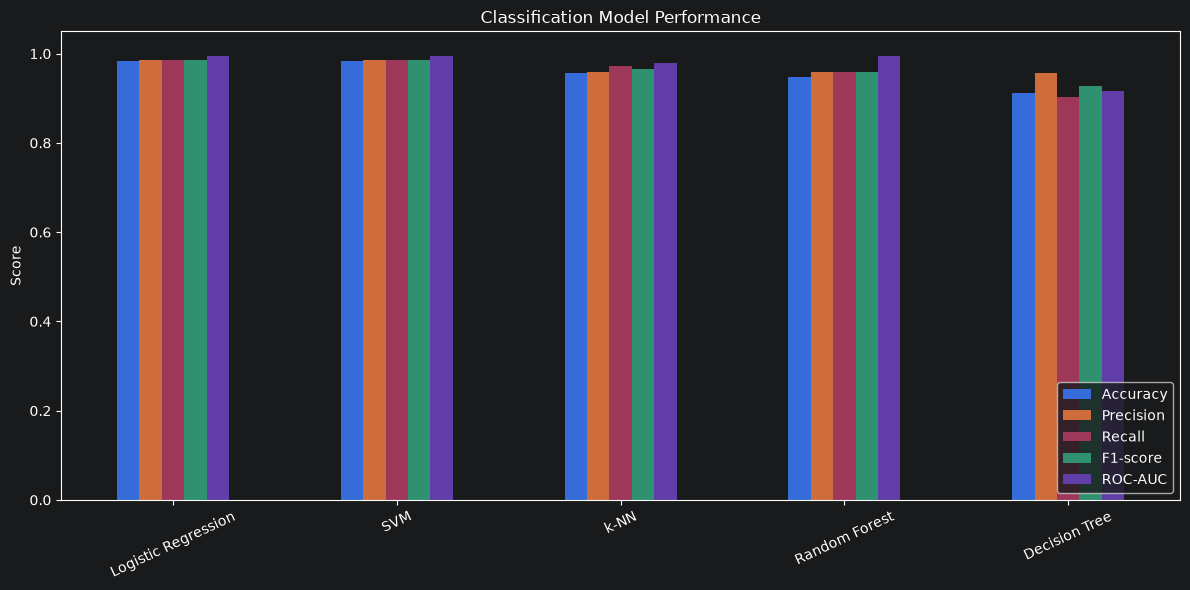

In [7]:
ax = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))

ax.set_title("Classification Model Performance")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=25)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Classification reports and confusion matrices


===== Logistic Regression =====
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



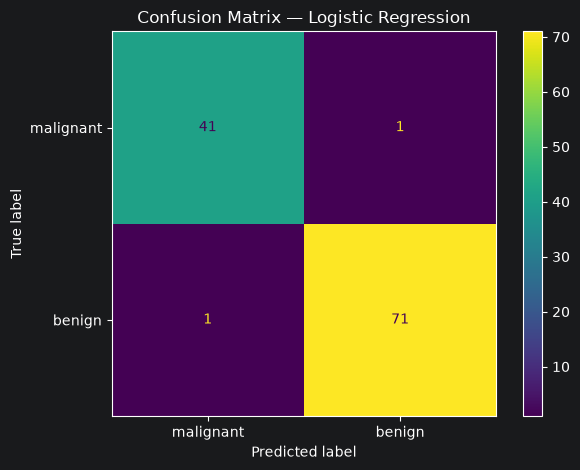


===== Decision Tree =====
              precision    recall  f1-score   support

   malignant     0.8478    0.9286    0.8864        42
      benign     0.9559    0.9028    0.9286        72

    accuracy                         0.9123       114
   macro avg     0.9019    0.9157    0.9075       114
weighted avg     0.9161    0.9123    0.9130       114



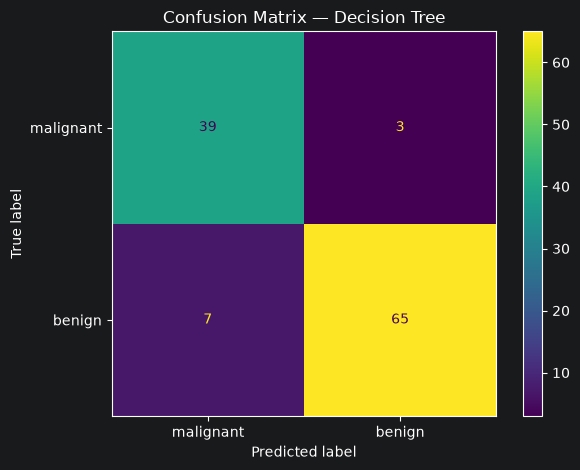


===== Random Forest =====
              precision    recall  f1-score   support

   malignant     0.9286    0.9286    0.9286        42
      benign     0.9583    0.9583    0.9583        72

    accuracy                         0.9474       114
   macro avg     0.9435    0.9435    0.9435       114
weighted avg     0.9474    0.9474    0.9474       114



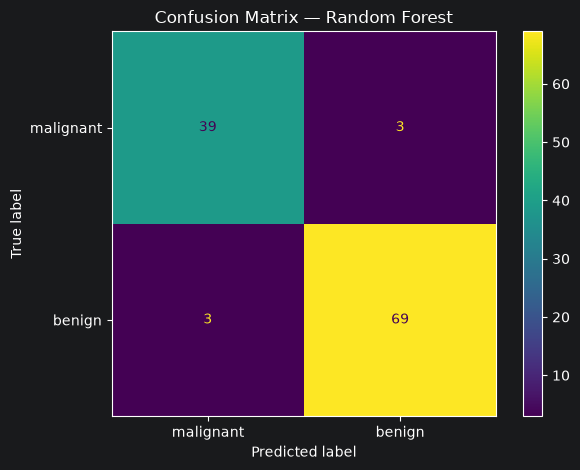


===== SVM =====
              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



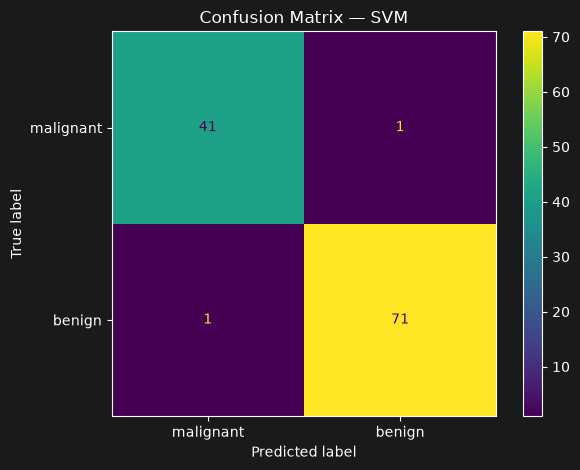


===== k-NN =====
              precision    recall  f1-score   support

   malignant     0.9512    0.9286    0.9398        42
      benign     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114



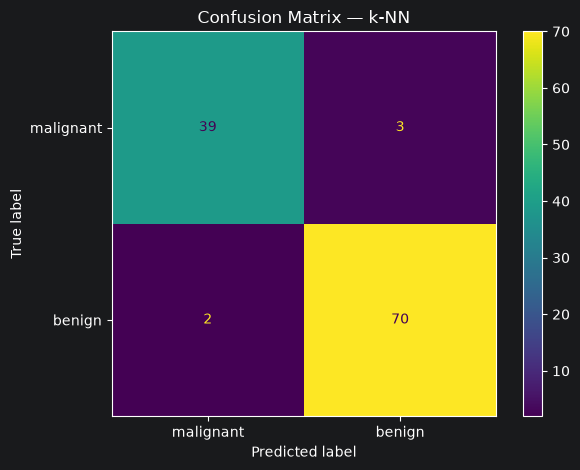

In [8]:
for name, y_pred in predictions.items():
    print(f"\n===== {name} =====")
    print(classification_report(
        y_test, y_pred,
        target_names=cancer.target_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=cancer.target_names
    )
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 7. Best and worst model by test accuracy

In [9]:
best_row = results_df.loc[results_df["Accuracy"].idxmax()]
worst_row = results_df.loc[results_df["Accuracy"].idxmin()]

print(f"Best model by test accuracy: {best_row['Model']} ({best_row['Accuracy']:.4f})")
print(f"Worst model by test accuracy: {worst_row['Model']} ({worst_row['Accuracy']:.4f})")
print("\nIf models tie, more than one model may be best.")

Best model by test accuracy: Logistic Regression (0.9825)
Worst model by test accuracy: Decision Tree (0.9123)

If models tie, more than one model may be best.


## 8. Conclusion

Use the model comparison table and chart to discuss the relative test performance. Logistic Regression and SVM often perform strongly on this dataset after standardisation, while a single Decision Tree may be less consistent because it can overfit. The exact ranking should be taken from the results generated by running this notebook.

Preprocessing was included to handle possible missing values and scale features for distance- and margin-based methods. A stratified holdout set was used for comparison. For a stronger study, tune hyperparameters with cross-validation and report class-wise metrics, particularly malignant recall.

**Note:** This is an educational machine-learning exercise and must not be used to diagnose patients.